# Timing comparison — A2
Offline A1 tables only. Synthetic fixtures are test data, not experimental evidence.
Configure explicit conditions/baseline and controls below. Failures, unknown outcomes,
exclusions and unsupported matches remain visible. No automatic outlier removal.


In [1]:
# Configuration: edit these paths for interactive use, or use the batch CLI.
import sys
from pathlib import Path

#ROOT = Path("/workspace")  # Repository mount inside Docker

candidates = [
    Path("/workspace"),
    Path("/home/timk/rmit/PQC-Framework-02"),
]

ROOT = next(
    (p for p in candidates
     if (p / "scripts/framework/timing_dataset_loader.py").is_file()),
    None,
)

if ROOT is None:
    raise RuntimeError("This notebook kernel cannot access the repository.")

sys.path.insert(0, str(ROOT / "scripts"))
print("Repository:", ROOT)

sys.path.insert(0, str(ROOT / "scripts"))

from framework.timing_dataset_loader import load_dataset

DATASET = ROOT / "results/analysis/secureboot_20260928_a1"
OUTPUT = ROOT / "results/analysis/secureboot_20260928_summary_01"

dataset = load_dataset(DATASET)
profiles = sorted({
    run["secure_boot"]
    for run in dataset.runs
    if run["secure_boot"] is not None
})

# Secure-boot profile identity changes intentionally with the treatment.
profile_hash_controls = sorted({
    "controls.profile_hashes." + key
    for run in dataset.runs
    for key in run["controls"].get("profile_hashes", {})
    if key.startswith("secure_boot:")
})

SPEC = {
    "conditions": {
        profile: {"secure_boot": profile}
        for profile in profiles
    },
    "baseline": "ecdsa_p256",
    "filters": {},
    "controls": ["target", "workload", "network_condition"],
    "treatment": [
        "secure_boot",
        "controls.choices.secure_boot",
        *profile_hash_controls,
    ],
    "not_applicable": {},
    "exclude_runs": {},
    "percentiles": [90, 95],
    "independent_runs": False,
    "seed": 20260928,
    "resamples": 2000,
    "confidence": 0.95,
}

SPEC

Repository: /home/timk/rmit/PQC-Framework-02


{'conditions': {'ecdsa_p256': {'secure_boot': 'ecdsa_p256'},
  'ecdsa_p384': {'secure_boot': 'ecdsa_p384'},
  'ecdsa_p521': {'secure_boot': 'ecdsa_p521'},
  'ed25519': {'secure_boot': 'ed25519'},
  'ed448': {'secure_boot': 'ed448'},
  'integrity_sha256': {'secure_boot': 'integrity_sha256'},
  'mldsa44': {'secure_boot': 'mldsa44'},
  'mldsa65': {'secure_boot': 'mldsa65'},
  'mldsa87': {'secure_boot': 'mldsa87'},
  'rsa2048': {'secure_boot': 'rsa2048'},
  'rsa3072': {'secure_boot': 'rsa3072'},
  'rsa4096': {'secure_boot': 'rsa4096'}},
 'baseline': 'ecdsa_p256',
 'filters': {},
 'controls': ['target', 'workload', 'network_condition'],
 'treatment': ['secure_boot',
  'controls.choices.secure_boot',
  'controls.profile_hashes.secure_boot:ecdsa_p256',
  'controls.profile_hashes.secure_boot:ecdsa_p384',
  'controls.profile_hashes.secure_boot:ecdsa_p521',
  'controls.profile_hashes.secure_boot:ed25519',
  'controls.profile_hashes.secure_boot:ed448',
  'controls.profile_hashes.secure_boot:integ

In [2]:
from framework.timing_summary import export_summary
from IPython.display import display, Image
import os
# Set True interactively, or pass --resources to the batch CLI.
INCLUDE_RESOURCES = os.environ.get("PQC_A3_RESOURCES", "0") == "1"
frames = export_summary(DATASET, SPEC, OUTPUT, resources=INCLUDE_RESOURCES)
display(frames["completeness"])


,condition,capture_class,evidence_class,metric,inventory_runs,excluded_runs,included_runs,completed_runs,failed_runs,unknown_runs,...,completion_ci_low,completion_ci_high,completion_ci_reason,capture_accepted_runs,valid_observations,unavailable_observations,contributing_runs,contributing_observations,contributing_iterations,runs_without_usable_metric
0,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,tls_handshake,10,0,10,10,0,0,...,None,None,independence_not_declared,10,10,0,10,10,10,0
1,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,mqtt_readiness,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,10,0,0,0,10
2,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,rtfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,0,0,0,0,10
3,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,rtlb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,0,0,0,0,10
4,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,ttfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,0,0,0,0,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,rtlb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,0,0,0,0,10
92,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,ttfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,0,0,0,0,10
93,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,ttlb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,0,0,0,0,10
94,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,req_tfb,10,0,10,10,0,0,...,None,None,independence_not_declared,10,0,0,0,0,0,10


Completion denominator = completed + failed included runs. Unknown outcomes and
explicit exclusions have separate counts. Latency is conditional on completed
execution, verified selected inputs, valid measurements and timing-policy eligibility.
Capture acceptance and measurement validity are separate. Repeated intra-run
observations are descriptive only. Wilson completion intervals and percentile
bootstrap median intervals require declared independent runs and sufficient counts.
Matching considers all recorded configured control properties, except explicitly
declared treatments/not-applicable properties. Unknown controls refuse matching.
ELF and credential identities are retained as provenance, not required equal.


,condition,capture_class,evidence_class,metric,unit,n_runs,n_observations,q1,median,q3,iqr,p90,p95,median_ci_low,median_ci_high,median_ci_reason
0,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,tls_handshake,us,10,10,955412.5,956396.0,959652.25,4239.75,962171.0,964785.5,None,None,independence_not_declared
1,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,mqtt_readiness,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared
2,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,rtfb,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared
3,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,rtlb,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared
4,ecdsa_p256,tls_runtime,stm32_st67_classical_tls_e2e,ttfb,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,rtlb,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared
92,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,ttfb,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared
93,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,ttlb,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared
94,rsa4096,tls_runtime,stm32_st67_classical_tls_e2e,req_tfb,us,0,0,None,None,None,None,None,None,None,None,independence_not_declared


,condition,baseline,metric,unit,delta_median,percent_difference,reason,percent_reason,baseline_runs,treatment_runs
0,ecdsa_p384,ecdsa_p256,tls_handshake,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,10,10
1,ecdsa_p384,ecdsa_p256,mqtt_readiness,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0
2,ecdsa_p384,ecdsa_p256,rtfb,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0
3,ecdsa_p384,ecdsa_p256,rtlb,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0
4,ecdsa_p384,ecdsa_p256,ttfb,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0
...,...,...,...,...,...,...,...,...,...,...
83,rsa4096,ecdsa_p256,rtlb,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0
84,rsa4096,ecdsa_p256,ttfb,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0
85,rsa4096,ecdsa_p256,ttlb,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0
86,rsa4096,ecdsa_p256,req_tfb,us,None,None,unknown_control:chunk_bytes;unknown_control:co...,unknown_control:chunk_bytes;unknown_control:co...,0,0


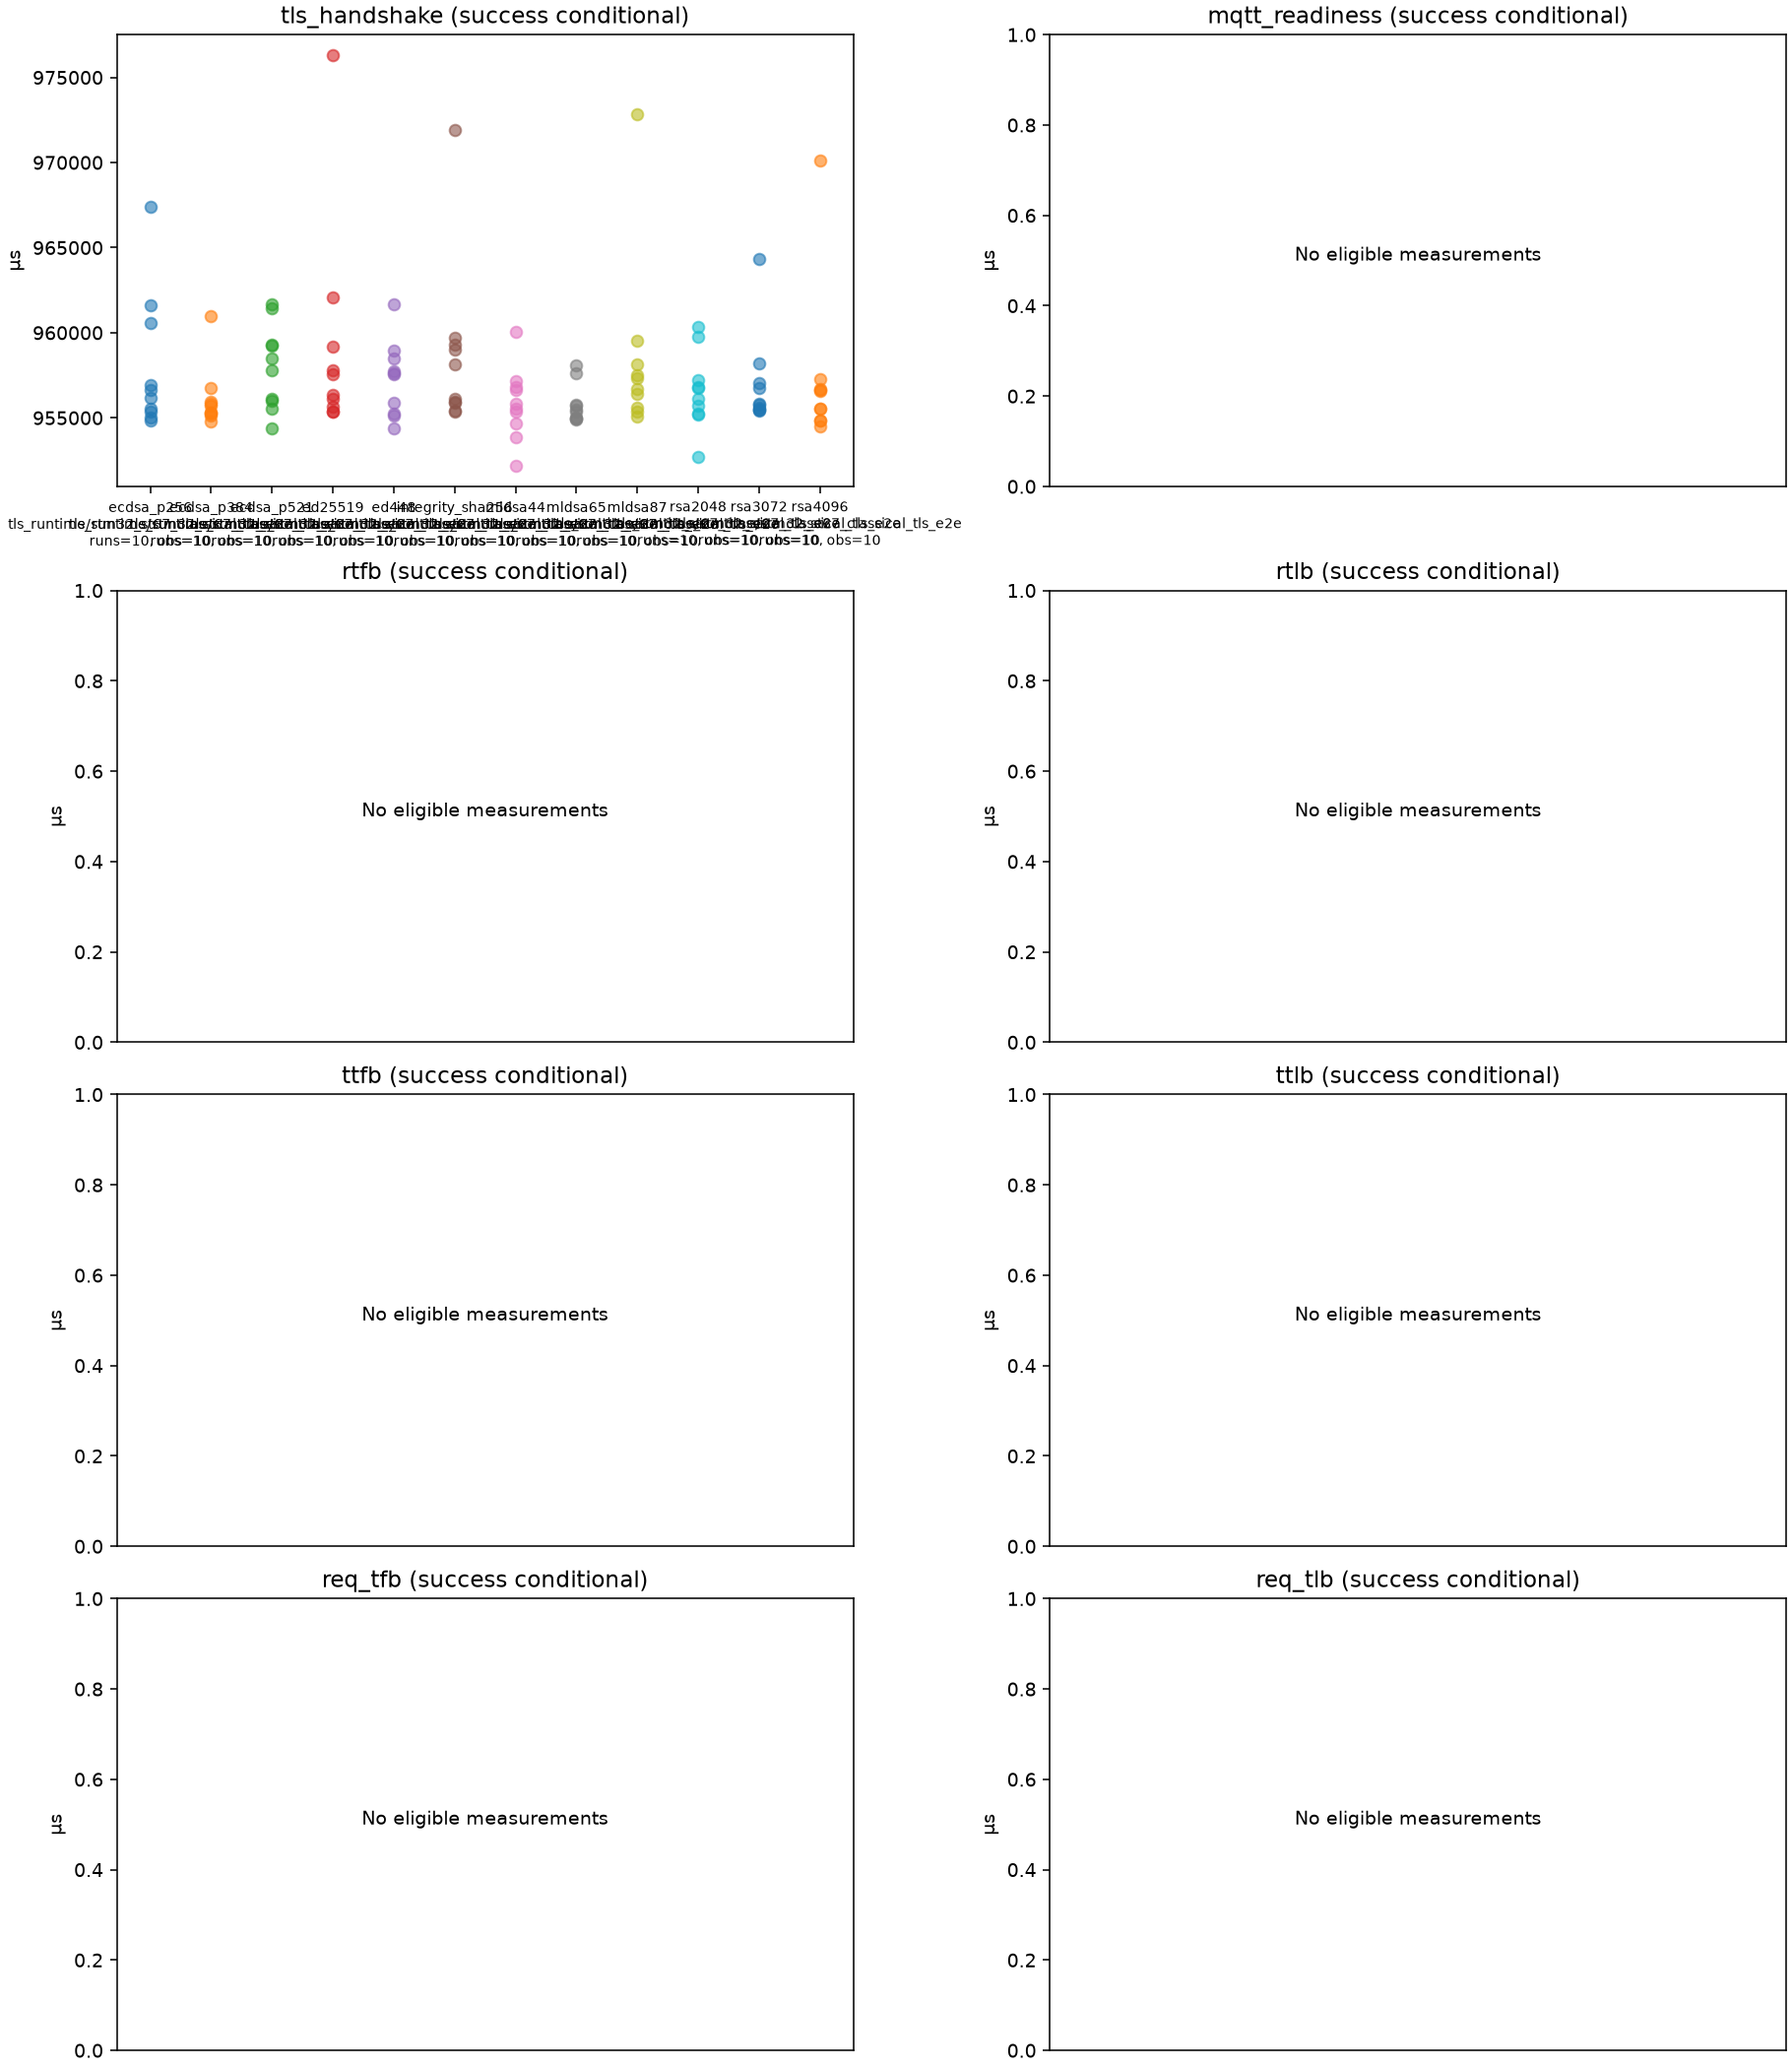

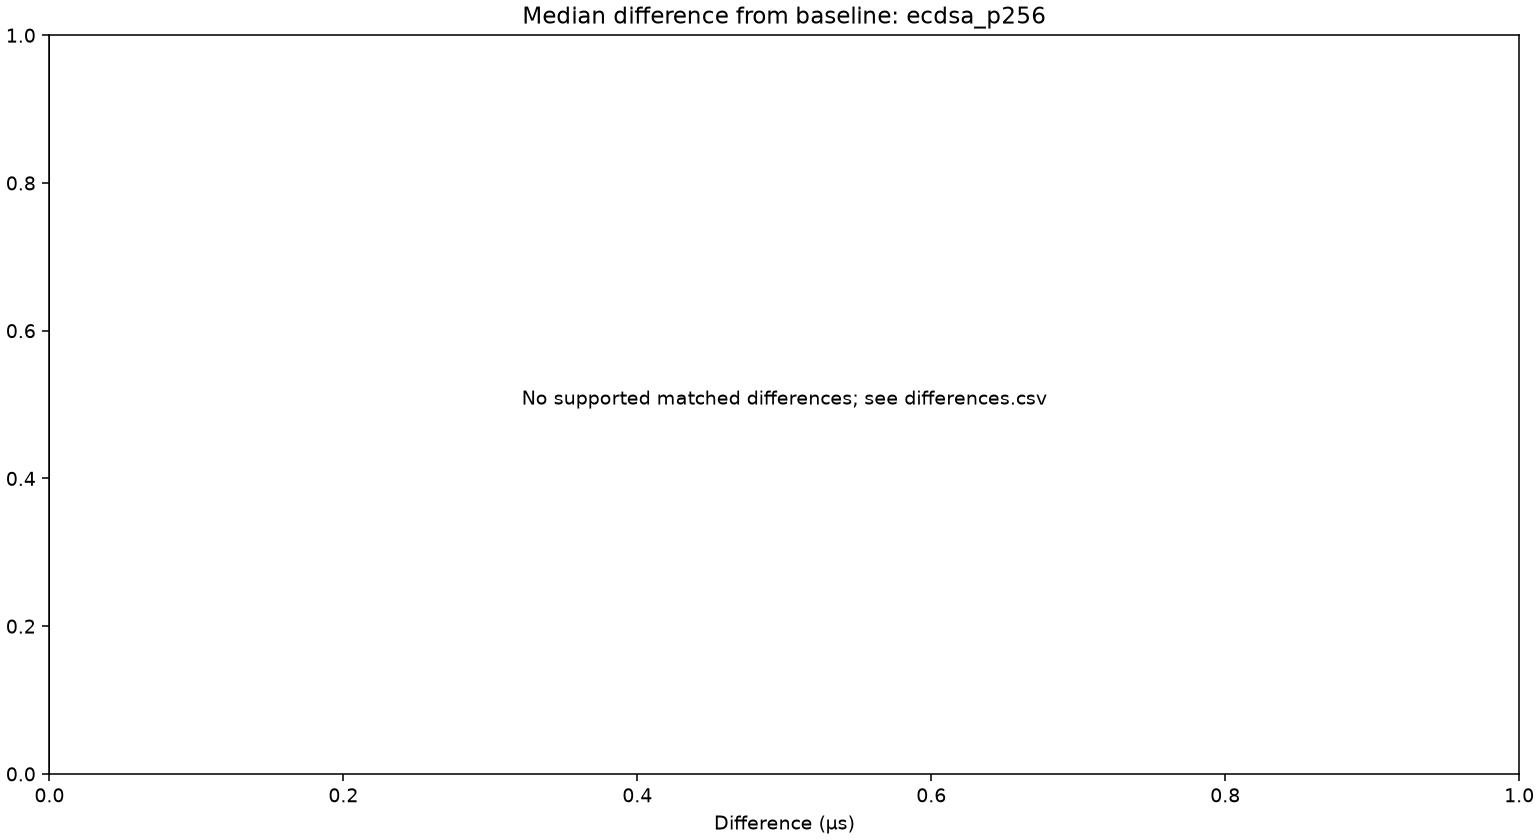

In [3]:
display(frames["distributions"])
display(frames["differences"])
display(Image(filename=str(OUTPUT / "timing-distributions.png")))
display(Image(filename=str(OUTPUT / "matched-differences.png")))


## Application resources — A3
Enable INCLUDE_RESOURCES above to verify retained resource inputs. Native values are bytes; 1 KiB = 1024 bytes. Static observations count unique ELF builds; runtime peaks retain their lifetime scope. Heap, task stack and workspace values overlap reserved storage. Regional peaks are not a simultaneous whole-system peak. Missing evidence and unsupported comparisons remain explicit.


In [ ]:
if INCLUDE_RESOURCES:
    for name in ("resource_builds", "resource_observations", "resource_distributions", "resource_differences"):
        display(frames[name])
